In [1]:
from pathlib import Path
import os

print("Directorio actual:", os.getcwd())

# Busca cualquier PNG/JPG bajo data/ (o bajo todo el directorio actual si no existe)
base = Path("/kaggle/input/datasets/jessicali9530/coil100/coil-100") if Path("/kaggle/input/datasets/jessicali9530/coil100/coil-100").exists() else Path(".")
found = list(base.rglob("*.png")) + list(base.rglob("*.jpg"))
print("Total de imágenes encontradas:", len(found))
for p in found[:10]:
    print(p)

Directorio actual: /kaggle/working
Total de imágenes encontradas: 7200
/kaggle/input/datasets/jessicali9530/coil100/coil-100/coil-100/obj100__0.png
/kaggle/input/datasets/jessicali9530/coil100/coil-100/coil-100/obj100__10.png
/kaggle/input/datasets/jessicali9530/coil100/coil-100/coil-100/obj100__100.png
/kaggle/input/datasets/jessicali9530/coil100/coil-100/coil-100/obj100__105.png
/kaggle/input/datasets/jessicali9530/coil100/coil-100/coil-100/obj100__110.png
/kaggle/input/datasets/jessicali9530/coil100/coil-100/coil-100/obj100__115.png
/kaggle/input/datasets/jessicali9530/coil100/coil-100/coil-100/obj100__120.png
/kaggle/input/datasets/jessicali9530/coil100/coil-100/coil-100/obj100__125.png
/kaggle/input/datasets/jessicali9530/coil100/coil-100/coil-100/obj100__130.png
/kaggle/input/datasets/jessicali9530/coil100/coil-100/coil-100/obj100__135.png


In [2]:
for root, dirs, files in os.walk("."):
    if root.count(os.sep) <= 2:
        print(root, "->", dirs[:5], files[:3])

. -> ['.virtual_documents'] []
./.virtual_documents -> [] ['__notebook_source__.ipynb']


In [3]:
import cv2, numpy as np, re
from pathlib import Path

RAW = Path("/kaggle/input/datasets/jessicali9530/coil100/coil-100")   # ajusta a la carpeta que te mostró el diagnóstico

# Indexa: objeto -> archivo de la vista más cercana a 0°
views = {}
for p in list(RAW.rglob("*.png")) + list(RAW.rglob("*.jpg")):
    m = re.match(r"obj(\d+)__(\d+)", p.stem)
    if m:
        obj, ang = int(m.group(1)), int(m.group(2))
        if obj not in views or ang < views[obj][0]:
            views[obj] = (ang, p)

print("Objetos encontrados:", len(views))

tiles = []
for i in range(1, 101):
    if i not in views:
        tiles.append(np.zeros((96, 96, 3), np.uint8))
        print("Falta objeto", i)
        continue
    img = cv2.imread(str(views[i][1]))
    img = cv2.resize(img, (96, 96))
    cv2.putText(img, str(i), (3, 14), cv2.FONT_HERSHEY_SIMPLEX, 0.5, (255,255,255), 1)
    tiles.append(img)

rows = [np.hstack(tiles[r*10:(r+1)*10]) for r in range(10)]
sheet = np.vstack(rows)

Path("figures").mkdir(exist_ok=True)
cv2.imwrite("figures/coil100_overview.png", sheet)

Objetos encontrados: 100


True

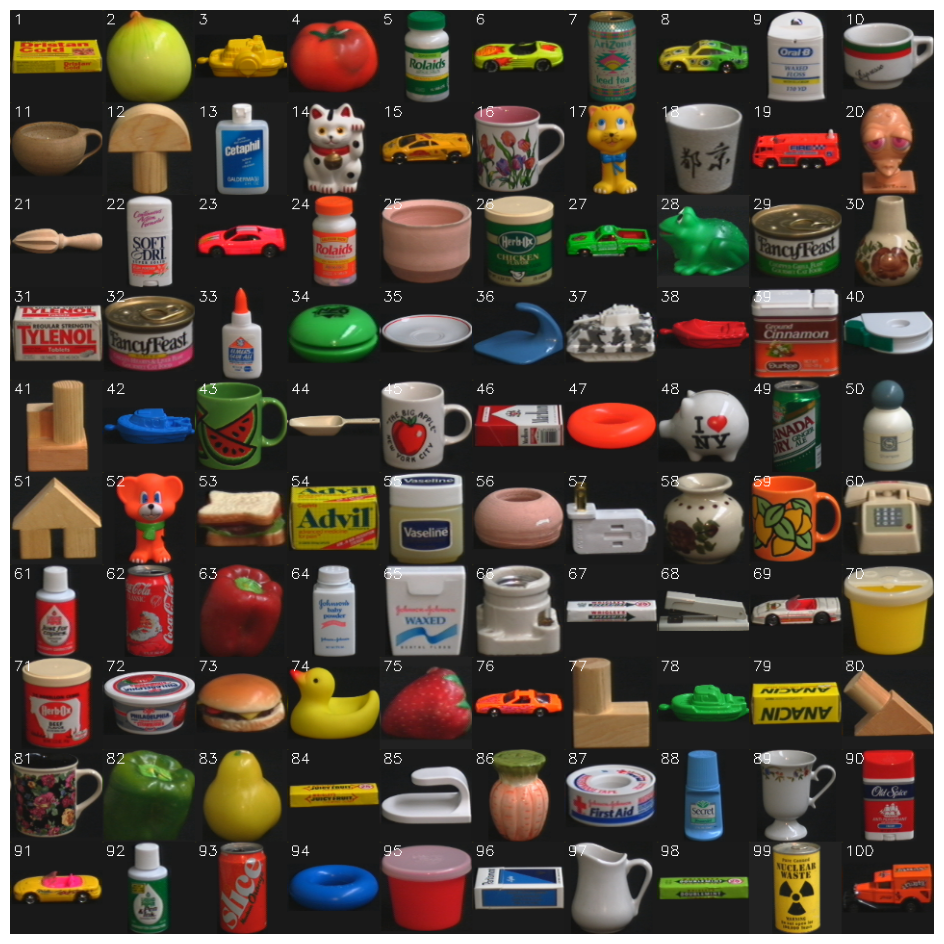

In [6]:
import matplotlib.pyplot as plt
plt.figure(figsize=(12, 12))
plt.imshow(cv2.cvtColor(sheet, cv2.COLOR_BGR2RGB))
plt.axis("off")
plt.show()

In [7]:
import os, re, shutil
from pathlib import Path

os.chdir("/kaggle/working")

SELECTED_OBJECTS = [43, 63, 68, 74, 75]
RAW_DIR = Path("/kaggle/input")        # rglob encuentra coil-100 dentro
OUTPUT_DIR = Path("data/processed")

if OUTPUT_DIR.exists():
    shutil.rmtree(OUTPUT_DIR)

counts = {}
for p in RAW_DIR.rglob("*.png"):
    m = re.match(r"obj(\d+)__(\d+)$", p.stem)
    if not m:
        continue
    obj, angle = int(m.group(1)), int(m.group(2))
    if obj not in SELECTED_OBJECTS:
        continue
    block = (angle // 5) // 4
    split = "test" if block % 5 == 4 else "train"
    dest = OUTPUT_DIR / split / f"obj{obj:03d}"
    dest.mkdir(parents=True, exist_ok=True)
    shutil.copy(p, dest / p.name)
    counts[(split, obj)] = counts.get((split, obj), 0) + 1

for k in sorted(counts):
    print(k, counts[k])

('test', 43) 12
('test', 63) 12
('test', 68) 12
('test', 74) 12
('test', 75) 12
('train', 43) 60
('train', 63) 60
('train', 68) 60
('train', 74) 60
('train', 75) 60


In [12]:
import cv2
import numpy as np
from skimage.feature import hog, local_binary_pattern

IMG_SIZE = 128

def extract_features(img_path):
    img = cv2.imread(str(img_path))
    if img is None:
        raise FileNotFoundError(f"No se pudo leer: {img_path}")
    img = cv2.resize(img, (IMG_SIZE, IMG_SIZE))

    hsv = cv2.cvtColor(img, cv2.COLOR_BGR2HSV)
    hist_h = cv2.calcHist([hsv], [0], None, [32], [0, 180])
    hist_s = cv2.calcHist([hsv], [1], None, [32], [0, 256])
    hist_v = cv2.calcHist([hsv], [2], None, [32], [0, 256])
    color_feat = np.concatenate([hist_h, hist_s, hist_v]).flatten()
    color_feat = color_feat / (color_feat.sum() + 1e-6)

    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
    hog_feat = hog(gray, orientations=9, pixels_per_cell=(16, 16),
                   cells_per_block=(2, 2), visualize=False)

    lbp = local_binary_pattern(gray, P=8, R=1, method="uniform")
    lbp_hist, _ = np.histogram(lbp.ravel(), bins=np.arange(0, 11), density=True)

    return np.concatenate([color_feat, hog_feat, lbp_hist]).astype(np.float32)

Train: 300 | Test: 60


Inferencia: 100%|██████████| 60/60 [00:00<00:00, 65.21it/s]


              precision    recall  f1-score   support

      obj043       1.00      1.00      1.00        12
      obj063       1.00      1.00      1.00        12
      obj068       1.00      1.00      1.00        12
      obj074       1.00      1.00      1.00        12
      obj075       1.00      1.00      1.00        12

    accuracy                           1.00        60
   macro avg       1.00      1.00      1.00        60
weighted avg       1.00      1.00      1.00        60

{
  "scenario": "clasico_secuencial",
  "accuracy": 1.0,
  "precision_macro": 1.0,
  "recall_macro": 1.0,
  "f1_macro": 1.0,
  "t_extract_train_s": 2.4037747590000436,
  "t_fit_s": 0.6324905429999035,
  "t_train_total_s": 3.036265301999947,
  "latency_mean_ms": 15.219139949995983,
  "latency_p95_ms": 16.535973599923178,
  "throughput_img_s": 65.70673528764442,
  "mem_start_mb": 291.9921875,
  "mem_peak_mb": 296.4375,
  "n_features": 1870
}


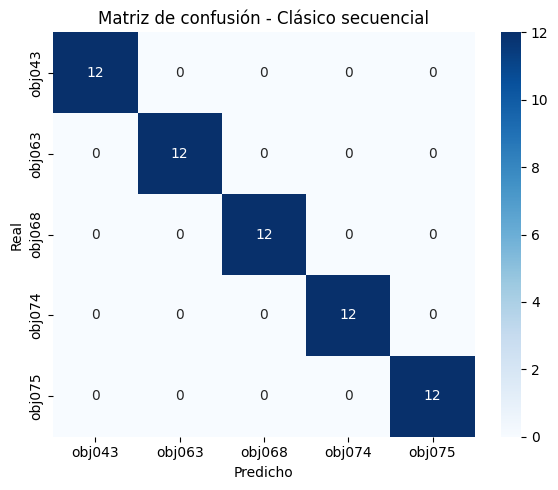

In [13]:
import json
import time
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import psutil
import seaborn as sns
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, classification_report,
                             confusion_matrix, precision_recall_fscore_support)
from tqdm import tqdm


def list_split(split):
    """Devuelve rutas y etiquetas, sin extraer características todavía."""
    paths, labels = [], []
    for class_dir in sorted(Path(f"data/processed/{split}").iterdir()):
        for p in sorted(class_dir.glob("*.png")):
            paths.append(p)
            labels.append(class_dir.name)
    return paths, np.array(labels)


def extract_all(paths, desc):
    return np.array([extract_features(p) for p in tqdm(paths, desc=desc)])


def rss_mb():
    return psutil.Process().memory_info().rss / 1024**2


def main():
    train_paths, y_train = list_split("train")
    test_paths, y_test = list_split("test")
    print(f"Train: {len(train_paths)} | Test: {len(test_paths)}")

    mem_start = rss_mb()

    # --- Extracción de características (train) ---
    t0 = time.perf_counter()
    X_train = extract_all(train_paths, "Features train")
    t_extract_train = time.perf_counter() - t0

    # --- Entrenamiento (secuencial: n_jobs=1) ---
    clf = RandomForestClassifier(n_estimators=100, n_jobs=1, random_state=42)
    t0 = time.perf_counter()
    clf.fit(X_train, y_train)
    t_fit = time.perf_counter() - t0

    # --- Inferencia imagen por imagen: extracción + predict ---
    latencies, y_pred = [], []
    for p in tqdm(test_paths, desc="Inferencia"):
        t0 = time.perf_counter()
        feat = extract_features(p)
        y_pred.append(clf.predict(feat.reshape(1, -1))[0])
        latencies.append(time.perf_counter() - t0)
    y_pred = np.array(y_pred)
    lat_ms = np.array(latencies) * 1000

    mem_peak = rss_mb()

    # --- Métricas ---
    acc = accuracy_score(y_test, y_pred)
    prec, rec, f1, _ = precision_recall_fscore_support(
        y_test, y_pred, average="macro", zero_division=0)
    labels = sorted(set(y_test))
    cm = confusion_matrix(y_test, y_pred, labels=labels)

    results = {
        "scenario": "clasico_secuencial",
        "accuracy": acc,
        "precision_macro": prec,
        "recall_macro": rec,
        "f1_macro": f1,
        "t_extract_train_s": t_extract_train,
        "t_fit_s": t_fit,
        "t_train_total_s": t_extract_train + t_fit,
        "latency_mean_ms": float(lat_ms.mean()),
        "latency_p95_ms": float(np.percentile(lat_ms, 95)),
        "throughput_img_s": float(len(test_paths) / np.sum(latencies)),
        "mem_start_mb": mem_start,
        "mem_peak_mb": mem_peak,
        "n_features": int(X_train.shape[1]),
    }

    print(classification_report(y_test, y_pred, zero_division=0))
    print(json.dumps(results, indent=2))

    # --- Guardado ---
    Path("results").mkdir(exist_ok=True)
    Path("figures").mkdir(exist_ok=True)
    with open("results/classic_sequential.json", "w") as f:
        json.dump(results, f, indent=2)
    joblib.dump(clf, "results/classic_model.joblib")

    plt.figure(figsize=(6, 5))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
                xticklabels=labels, yticklabels=labels)
    plt.xlabel("Predicho")
    plt.ylabel("Real")
    plt.title("Matriz de confusión - Clásico secuencial")
    plt.tight_layout()
    plt.savefig("figures/cm_classic_sequential.png", dpi=150)
    plt.show()

    return results


results = main()

In [14]:
import os
os.rename("results/classic_sequential.json", "results/classic_sequential_A.json")
os.rename("figures/cm_classic_sequential.png", "figures/cm_classic_sequential_A.png")

---------------------ESCENARIO FACIL CULMINADO---------------------------------------

In [15]:
import os, re, shutil
from pathlib import Path

os.chdir("/kaggle/working")

SELECTED_OBJECTS = [43, 63, 68, 74, 75]
RAW_DIR = Path("/kaggle/input")
OUTPUT_DIR = Path("data/processed")

if OUTPUT_DIR.exists():
    shutil.rmtree(OUTPUT_DIR)

counts = {}
for p in RAW_DIR.rglob("*.png"):
    m = re.match(r"obj(\d+)__(\d+)$", p.stem)
    if not m:
        continue
    obj, angle = int(m.group(1)), int(m.group(2))
    if obj not in SELECTED_OBJECTS:
        continue
    split = "train" if angle < 180 else "test"
    dest = OUTPUT_DIR / split / f"obj{obj:03d}"
    dest.mkdir(parents=True, exist_ok=True)
    shutil.copy(p, dest / p.name)
    counts[(split, obj)] = counts.get((split, obj), 0) + 1

for k in sorted(counts):
    print(k, counts[k])

('test', 43) 36
('test', 63) 36
('test', 68) 36
('test', 74) 36
('test', 75) 36
('train', 43) 36
('train', 63) 36
('train', 68) 36
('train', 74) 36
('train', 75) 36


Train: 180 | Test: 180


Inferencia: 100%|██████████| 180/180 [00:02<00:00, 66.63it/s]


              precision    recall  f1-score   support

      obj043       1.00      1.00      1.00        36
      obj063       0.77      1.00      0.87        36
      obj068       1.00      1.00      1.00        36
      obj074       1.00      1.00      1.00        36
      obj075       1.00      0.69      0.82        36

    accuracy                           0.94       180
   macro avg       0.95      0.94      0.94       180
weighted avg       0.95      0.94      0.94       180

{
  "scenario": "clasico_secuencial_B",
  "accuracy": 0.9388888888888889,
  "precision_macro": 0.9531914893617021,
  "recall_macro": 0.9388888888888889,
  "f1_macro": 0.9374284021331227,
  "t_extract_train_s": 1.4413072669999565,
  "t_fit_s": 0.4068894229999387,
  "t_train_total_s": 1.8481966899998952,
  "latency_mean_ms": 14.88152958889436,
  "latency_p95_ms": 15.798894650038164,
  "throughput_img_s": 67.19739352238832,
  "mem_start_mb": 303.09375,
  "mem_peak_mb": 303.109375,
  "n_features": 1870
}


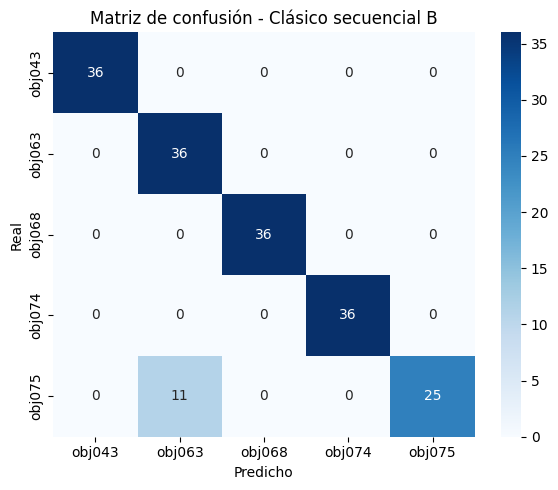

In [16]:
import json
import time
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import psutil
import seaborn as sns
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, classification_report,
                             confusion_matrix, precision_recall_fscore_support)
from tqdm import tqdm


def list_split(split):
    paths, labels = [], []
    for class_dir in sorted(Path(f"data/processed/{split}").iterdir()):
        for p in sorted(class_dir.glob("*.png")):
            paths.append(p)
            labels.append(class_dir.name)
    return paths, np.array(labels)


def extract_all(paths, desc):
    return np.array([extract_features(p) for p in tqdm(paths, desc=desc)])


def rss_mb():
    return psutil.Process().memory_info().rss / 1024**2


def main():
    train_paths, y_train = list_split("train")
    test_paths, y_test = list_split("test")
    print(f"Train: {len(train_paths)} | Test: {len(test_paths)}")

    mem_start = rss_mb()

    t0 = time.perf_counter()
    X_train = extract_all(train_paths, "Features train")
    t_extract_train = time.perf_counter() - t0

    clf = RandomForestClassifier(n_estimators=100, n_jobs=1, random_state=42)
    t0 = time.perf_counter()
    clf.fit(X_train, y_train)
    t_fit = time.perf_counter() - t0

    latencies, y_pred = [], []
    for p in tqdm(test_paths, desc="Inferencia"):
        t0 = time.perf_counter()
        feat = extract_features(p)
        y_pred.append(clf.predict(feat.reshape(1, -1))[0])
        latencies.append(time.perf_counter() - t0)
    y_pred = np.array(y_pred)
    lat_ms = np.array(latencies) * 1000

    mem_peak = rss_mb()

    acc = accuracy_score(y_test, y_pred)
    prec, rec, f1, _ = precision_recall_fscore_support(
        y_test, y_pred, average="macro", zero_division=0)
    labels = sorted(set(y_test))
    cm = confusion_matrix(y_test, y_pred, labels=labels)

    results = {
        "scenario": "clasico_secuencial_B",
        "accuracy": acc,
        "precision_macro": prec,
        "recall_macro": rec,
        "f1_macro": f1,
        "t_extract_train_s": t_extract_train,
        "t_fit_s": t_fit,
        "t_train_total_s": t_extract_train + t_fit,
        "latency_mean_ms": float(lat_ms.mean()),
        "latency_p95_ms": float(np.percentile(lat_ms, 95)),
        "throughput_img_s": float(len(test_paths) / np.sum(latencies)),
        "mem_start_mb": mem_start,
        "mem_peak_mb": mem_peak,
        "n_features": int(X_train.shape[1]),
    }

    print(classification_report(y_test, y_pred, zero_division=0))
    print(json.dumps(results, indent=2))

    Path("results").mkdir(exist_ok=True)
    Path("figures").mkdir(exist_ok=True)
    with open("results/classic_sequential_B.json", "w") as f:
        json.dump(results, f, indent=2)
    joblib.dump(clf, "results/classic_model_B.joblib")

    plt.figure(figsize=(6, 5))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
                xticklabels=labels, yticklabels=labels)
    plt.xlabel("Predicho")
    plt.ylabel("Real")
    plt.title("Matriz de confusión - Clásico secuencial B")
    plt.tight_layout()
    plt.savefig("figures/cm_classic_sequential_B.png", dpi=150)
    plt.show()

    return results


results_B = main()

----------------- ESCENARIO INTERMEDIO CULMINADO ----------------------

In [18]:
import json
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import psutil
import seaborn as sns
import torch
import torch.nn as nn
from PIL import Image
from sklearn.metrics import (accuracy_score, classification_report,
                             confusion_matrix, precision_recall_fscore_support)
from torch.utils.data import DataLoader
from torchvision import datasets, models, transforms

torch.manual_seed(42)
np.random.seed(42)

train_device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Entrenando en:", train_device)

IMG_SIZE = 128
tf = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225]),
])

train_ds = datasets.ImageFolder("data/processed/train", transform=tf)
test_ds = datasets.ImageFolder("data/processed/test", transform=tf)
print("Clases:", train_ds.classes)
print(f"Train: {len(train_ds)} | Test: {len(test_ds)}")

train_loader = DataLoader(train_ds, batch_size=32, shuffle=True, num_workers=2)

# Modelo compacto con transfer learning
model = models.mobilenet_v2(weights="DEFAULT")
model.classifier[1] = nn.Linear(model.last_channel, len(train_ds.classes))
model = model.to(train_device)

n_params = sum(p.numel() for p in model.parameters())
print(f"Parámetros: {n_params:,} (~{n_params * 4 / 1024**2:.1f} MB en float32)")

criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=1e-4)

EPOCHS = 8
t0 = time.perf_counter()
model.train()
for epoch in range(EPOCHS):
    running_loss, correct, total = 0.0, 0, 0
    for images, labels in train_loader:
        images, labels = images.to(train_device), labels.to(train_device)
        optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()
        running_loss += loss.item() * labels.size(0)
        correct += (outputs.argmax(1) == labels).sum().item()
        total += labels.size(0)
    print(f"Epoch {epoch+1}/{EPOCHS} | loss {running_loss/total:.4f} | "
          f"train acc {100*correct/total:.1f}%")
t_train_total = time.perf_counter() - t0
print(f"Tiempo de entrenamiento: {t_train_total:.1f} s")

Path("results").mkdir(exist_ok=True)
Path("figures").mkdir(exist_ok=True)
torch.save(model.state_dict(), "results/cnn_mobilenet_B.pth")

Entrenando en: cuda
Clases: ['obj043', 'obj063', 'obj068', 'obj074', 'obj075']
Train: 180 | Test: 180
Downloading: "https://download.pytorch.org/models/mobilenet_v2-7ebf99e0.pth" to /root/.cache/torch/hub/checkpoints/mobilenet_v2-7ebf99e0.pth


100%|██████████| 13.6M/13.6M [00:00<00:00, 84.4MB/s]


Parámetros: 2,230,277 (~8.5 MB en float32)
Epoch 1/8 | loss 1.4249 | train acc 43.9%
Epoch 2/8 | loss 0.8796 | train acc 97.2%
Epoch 3/8 | loss 0.5476 | train acc 100.0%
Epoch 4/8 | loss 0.3131 | train acc 100.0%
Epoch 5/8 | loss 0.2080 | train acc 100.0%
Epoch 6/8 | loss 0.1228 | train acc 100.0%
Epoch 7/8 | loss 0.0981 | train acc 100.0%
Epoch 8/8 | loss 0.0944 | train acc 100.0%
Tiempo de entrenamiento: 5.2 s


              precision    recall  f1-score   support

      obj043       1.00      1.00      1.00        36
      obj063       1.00      1.00      1.00        36
      obj068       1.00      1.00      1.00        36
      obj074       1.00      1.00      1.00        36
      obj075       1.00      1.00      1.00        36

    accuracy                           1.00       180
   macro avg       1.00      1.00      1.00       180
weighted avg       1.00      1.00      1.00       180

{
  "scenario": "cnn_mobilenet_cpu_B",
  "accuracy": 1.0,
  "precision_macro": 1.0,
  "recall_macro": 1.0,
  "f1_macro": 1.0,
  "t_train_total_s": 5.221548517999963,
  "train_device": "cuda",
  "latency_mean_ms": 19.29428065000896,
  "latency_p95_ms": 20.878668900013494,
  "throughput_img_s": 51.82883042594985,
  "mem_start_mb": 1537.86328125,
  "mem_peak_mb": 1540.57421875,
  "n_params": 2230277
}


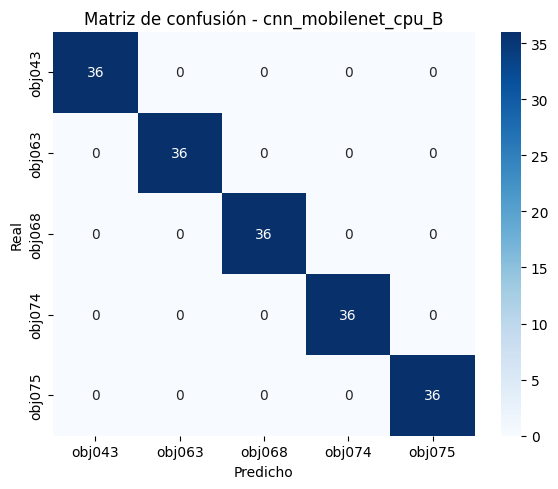

In [19]:
def rss_mb():
    return psutil.Process().memory_info().rss / 1024**2


def evaluate_per_image(model, device, scenario):
    model = model.to(device).eval()
    classes = test_ds.classes

    # Calentamiento (la primera inferencia siempre es más lenta)
    dummy = torch.randn(1, 3, IMG_SIZE, IMG_SIZE).to(device)
    with torch.no_grad():
        for _ in range(5):
            model(dummy)

    if device.type == "cuda":
        torch.cuda.reset_peak_memory_stats()
    mem_start = rss_mb()

    latencies, y_true, y_pred = [], [], []
    for path, label in test_ds.samples:
        t0 = time.perf_counter()
        img = Image.open(path).convert("RGB")
        x = tf(img).unsqueeze(0).to(device)
        with torch.no_grad():
            pred = model(x).argmax(1).item()   # .item() sincroniza con la GPU
        latencies.append(time.perf_counter() - t0)
        y_true.append(classes[label])
        y_pred.append(classes[pred])

    mem_peak = rss_mb()
    lat_ms = np.array(latencies) * 1000
    y_true, y_pred = np.array(y_true), np.array(y_pred)

    acc = accuracy_score(y_true, y_pred)
    prec, rec, f1, _ = precision_recall_fscore_support(
        y_true, y_pred, average="macro", zero_division=0)
    cm = confusion_matrix(y_true, y_pred, labels=classes)

    results = {
        "scenario": scenario,
        "accuracy": acc,
        "precision_macro": prec,
        "recall_macro": rec,
        "f1_macro": f1,
        "t_train_total_s": t_train_total,
        "train_device": str(train_device),
        "latency_mean_ms": float(lat_ms.mean()),
        "latency_p95_ms": float(np.percentile(lat_ms, 95)),
        "throughput_img_s": float(len(latencies) / np.sum(latencies)),
        "mem_start_mb": mem_start,
        "mem_peak_mb": mem_peak,
        "n_params": int(n_params),
    }
    if device.type == "cuda":
        results["gpu_mem_peak_mb"] = torch.cuda.max_memory_allocated() / 1024**2

    print(classification_report(y_true, y_pred, zero_division=0))
    print(json.dumps(results, indent=2))

    with open(f"results/{scenario}.json", "w") as f:
        json.dump(results, f, indent=2)

    plt.figure(figsize=(6, 5))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
                xticklabels=classes, yticklabels=classes)
    plt.xlabel("Predicho")
    plt.ylabel("Real")
    plt.title(f"Matriz de confusión - {scenario}")
    plt.tight_layout()
    plt.savefig(f"figures/cm_{scenario}.png", dpi=150)
    plt.show()
    return results


results_cnn_cpu = evaluate_per_image(model, torch.device("cpu"), "cnn_mobilenet_cpu_B")

La CNN resolvió justo lo que le costó al clásico: el pimiento (63) y la fresa (75), que el clásico confundía, ahora salen perfectos.

              precision    recall  f1-score   support

      obj043       1.00      1.00      1.00        36
      obj063       1.00      1.00      1.00        36
      obj068       1.00      1.00      1.00        36
      obj074       1.00      1.00      1.00        36
      obj075       1.00      1.00      1.00        36

    accuracy                           1.00       180
   macro avg       1.00      1.00      1.00       180
weighted avg       1.00      1.00      1.00       180

{
  "scenario": "cnn_mobilenet_gpu_B",
  "accuracy": 1.0,
  "precision_macro": 1.0,
  "recall_macro": 1.0,
  "f1_macro": 1.0,
  "t_train_total_s": 5.221548517999963,
  "train_device": "cuda",
  "latency_mean_ms": 7.827837550001328,
  "latency_p95_ms": 8.53924794996601,
  "throughput_img_s": 127.7492019491169,
  "mem_start_mb": 1543.55078125,
  "mem_peak_mb": 1543.5546875,
  "n_params": 2230277,
  "gpu_mem_peak_mb": 59.88818359375
}


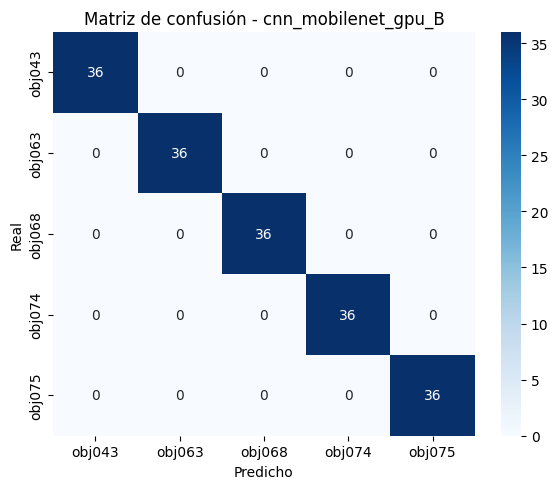

In [20]:
#celda 9:
if torch.cuda.is_available():
    results_cnn_gpu = evaluate_per_image(model, torch.device("cuda"), "cnn_mobilenet_gpu_B")
else:
    print("No hay GPU disponible: se omite este escenario.")

Imágenes: 360 | CPUs disponibles: 4
Secuencial: 2.778 s
2 procesos: 1.522 s | speedup 1.82x | eficiencia 91% | mismos resultados: True
4 procesos: 1.395 s | speedup 1.99x | eficiencia 50% | mismos resultados: True


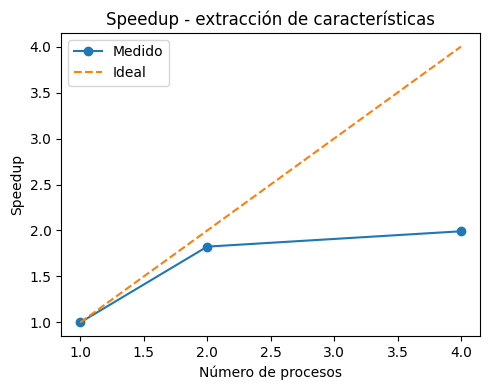

In [21]:
import os, time, json
import multiprocessing as mp
from pathlib import Path

import cv2
import matplotlib.pyplot as plt
import numpy as np

cv2.setNumThreads(1)   # evita que OpenCV use hilos extra dentro de cada proceso

all_paths = sorted(Path("data/processed").rglob("*.png"))
n_cpu = os.cpu_count() or 1
print(f"Imágenes: {len(all_paths)} | CPUs disponibles: {n_cpu}")


def _worker(p):
    return extract_features(p)


def run_sequential():
    return [_worker(p) for p in all_paths]


def run_parallel(n_proc):
    ctx = mp.get_context("fork")
    with ctx.Pool(processes=n_proc) as pool:
        return pool.map(_worker, all_paths, chunksize=8)


REPS = 3
proc_list = [p for p in [1, 2, 4, 8] if p <= n_cpu]

run_sequential()   # calentamiento (caché de disco)

# Baseline secuencial: bucle simple, sin Pool
t_seq_runs = []
for _ in range(REPS):
    t0 = time.perf_counter()
    feats_seq = run_sequential()
    t_seq_runs.append(time.perf_counter() - t0)
t_seq = float(np.median(t_seq_runs))
print(f"Secuencial: {t_seq:.3f} s")

rows = [{"processes": 1, "time_s": t_seq, "speedup": 1.0, "efficiency": 1.0,
         "throughput_img_s": len(all_paths) / t_seq}]

for n_proc in [p for p in proc_list if p > 1]:
    runs = []
    for _ in range(REPS):
        t0 = time.perf_counter()
        feats_par = run_parallel(n_proc)
        runs.append(time.perf_counter() - t0)
    t_par = float(np.median(runs))
    speedup = t_seq / t_par
    rows.append({"processes": n_proc, "time_s": t_par, "speedup": speedup,
                 "efficiency": speedup / n_proc,
                 "throughput_img_s": len(all_paths) / t_par})
    ok = np.allclose(np.array(feats_seq), np.array(feats_par))
    print(f"{n_proc} procesos: {t_par:.3f} s | speedup {speedup:.2f}x | "
          f"eficiencia {speedup/n_proc:.0%} | mismos resultados: {ok}")

Path("results").mkdir(exist_ok=True)
Path("figures").mkdir(exist_ok=True)
with open("results/classic_parallel_B.json", "w") as f:
    json.dump({"scenario": "clasico_paralelo_B", "n_images": len(all_paths),
               "n_cpu": n_cpu, "reps": REPS, "runs": rows}, f, indent=2)

procs = [r["processes"] for r in rows]
plt.figure(figsize=(5, 4))
plt.plot(procs, [r["speedup"] for r in rows], "o-", label="Medido")
plt.plot(procs, procs, "--", label="Ideal")
plt.xlabel("Número de procesos")
plt.ylabel("Speedup")
plt.title("Speedup - extracción de características")
plt.legend()
plt.tight_layout()
plt.savefig("figures/speedup_classic_parallel_B.png", dpi=150)
plt.show()

Epoch 1/8 | loss 1.5159 | train acc 36.1%
Epoch 2/8 | loss 1.1262 | train acc 78.3%
Epoch 3/8 | loss 0.8873 | train acc 91.7%
Epoch 4/8 | loss 0.6475 | train acc 98.9%
Epoch 5/8 | loss 0.5095 | train acc 100.0%
Epoch 6/8 | loss 0.3741 | train acc 100.0%
Epoch 7/8 | loss 0.3185 | train acc 100.0%
Epoch 8/8 | loss 0.2808 | train acc 99.4%
Tiempo de entrenamiento: 3.0 s
              precision    recall  f1-score   support

      obj043       1.00      1.00      1.00        36
      obj063       1.00      0.97      0.99        36
      obj068       1.00      1.00      1.00        36
      obj074       1.00      1.00      1.00        36
      obj075       0.97      1.00      0.99        36

    accuracy                           0.99       180
   macro avg       0.99      0.99      0.99       180
weighted avg       0.99      0.99      0.99       180

{
  "scenario": "cnn_mobilenet_cpu_64_B",
  "accuracy": 0.9944444444444445,
  "precision_macro": 0.9945945945945945,
  "recall_macro": 0.9944

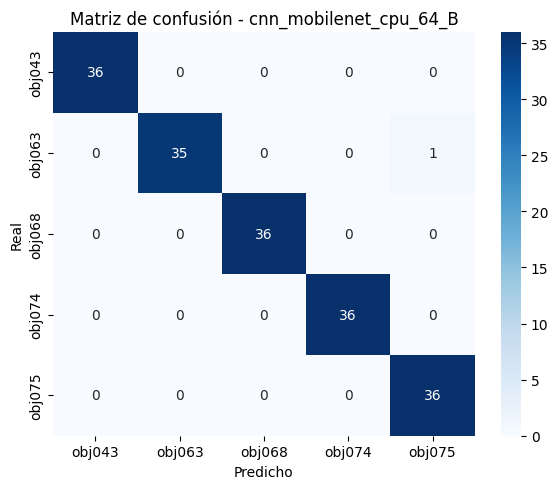

In [22]:
#celda 11
# Guardar las variables del escenario 128 para restaurarlas al final
_bak = dict(IMG_SIZE=IMG_SIZE, tf=tf, test_ds=test_ds,
            t_train_total=t_train_total, n_params=n_params)

IMG64 = 64
tf64 = transforms.Compose([
    transforms.Resize((IMG64, IMG64)),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225]),
])
train_ds64 = datasets.ImageFolder("data/processed/train", transform=tf64)
test_ds64 = datasets.ImageFolder("data/processed/test", transform=tf64)
train_loader64 = DataLoader(train_ds64, batch_size=32, shuffle=True, num_workers=2)

torch.manual_seed(42)
model64 = models.mobilenet_v2(weights="DEFAULT")
model64.classifier[1] = nn.Linear(model64.last_channel, len(train_ds64.classes))
model64 = model64.to(train_device)
n_params64 = sum(p.numel() for p in model64.parameters())

criterion64 = nn.CrossEntropyLoss()
optimizer64 = torch.optim.Adam(model64.parameters(), lr=1e-4)

t0 = time.perf_counter()
model64.train()
for epoch in range(EPOCHS):
    running_loss, correct, total = 0.0, 0, 0
    for images, labels in train_loader64:
        images, labels = images.to(train_device), labels.to(train_device)
        optimizer64.zero_grad()
        outputs = model64(images)
        loss = criterion64(outputs, labels)
        loss.backward()
        optimizer64.step()
        running_loss += loss.item() * labels.size(0)
        correct += (outputs.argmax(1) == labels).sum().item()
        total += labels.size(0)
    print(f"Epoch {epoch+1}/{EPOCHS} | loss {running_loss/total:.4f} | "
          f"train acc {100*correct/total:.1f}%")
t_train64 = time.perf_counter() - t0
print(f"Tiempo de entrenamiento: {t_train64:.1f} s")

torch.save(model64.state_dict(), "results/cnn_mobilenet_64_B.pth")

# Evaluar con la misma función de la Celda 8, apuntando a las variables de 64x64
IMG_SIZE, tf, test_ds = IMG64, tf64, test_ds64
t_train_total, n_params = t_train64, n_params64
results_cnn64 = evaluate_per_image(model64, torch.device("cpu"), "cnn_mobilenet_cpu_64_B")

# Restaurar las variables del escenario 128
globals().update(_bak)

In [24]:
#antes de seleccionar 12, no correr
import json
p = "results/classic_sequential_A.json"
d = json.load(open(p))
d["scenario"] = "clasico_secuencial_A"
json.dump(d, open(p, "w"), indent=2)

In [25]:
#celda 12:
import json
import pandas as pd
from pathlib import Path

rows = []
for f in sorted(Path("results").glob("*.json")):
    d = json.load(open(f))
    if isinstance(d, dict) and "accuracy" in d:   # salta el JSON del paralelo
        rows.append(d)

df = pd.DataFrame(rows)
cols = ["scenario", "accuracy", "f1_macro", "latency_mean_ms", "latency_p95_ms",
        "throughput_img_s", "mem_peak_mb", "t_train_total_s"]
df = df[[c for c in cols if c in df.columns]].round(3)
df.to_csv("results/comparacion.csv", index=False)
df

,scenario,accuracy,f1_macro,latency_mean_ms,latency_p95_ms,throughput_img_s,mem_peak_mb,t_train_total_s
0,clasico_secuencial_A,1.000,1.000,15.219,16.536,65.707,296.438,3.036
1,clasico_secuencial_B,0.939,0.937,14.882,15.799,67.197,303.109,1.848
2,cnn_mobilenet_cpu_64_B,0.994,0.994,14.089,16.348,70.976,1563.520,2.954
3,cnn_mobilenet_cpu_B,1.000,1.000,19.294,20.879,51.829,1540.574,5.222
4,cnn_mobilenet_gpu_B,1.000,1.000,7.828,8.539,127.749,1543.555,5.222


In [26]:
import json
print(json.dumps(json.load(open("results/classic_parallel_B.json")), indent=2))

{
  "scenario": "clasico_paralelo_B",
  "n_images": 360,
  "n_cpu": 4,
  "reps": 3,
  "runs": [
    {
      "processes": 1,
      "time_s": 2.7777660560000186,
      "speedup": 1.0,
      "efficiency": 1.0,
      "throughput_img_s": 129.60054689357094
    },
    {
      "processes": 2,
      "time_s": 1.5224395810000715,
      "speedup": 1.8245492896180082,
      "efficiency": 0.9122746448090041,
      "throughput_img_s": 236.46258576877023
    },
    {
      "processes": 4,
      "time_s": 1.3947523809999893,
      "speedup": 1.9915836630502515,
      "efficiency": 0.49789591576256287,
      "throughput_img_s": 258.11033191561387
    }
  ]
}
